# Complexité empirique de v1LD (B&B multi-dimensionnel)

Benchmark du temps de calcul par itération de sous-gradient pour `MKPProblemBnB` sur les instances Pisinger (weakly correlated, α=0.5).

`solve_zeta` résout un MKP à **m contraintes** par B&B (borne surrogate de Dantzig par colonne).  
Complexité par nœud : O(m × n). Nombre de nœuds : O(2^{k_m}) avec k_m = taille du core multi-dim.

**Variables étudiées :** n (items), m (contraintes), N (scénarios)

In [4]:
# ── Paramètres ────────────────────────────────────────────────────────────────
N_VALUES  = [5, 10, 20, 30]
M_VALUES  = [2, 5, 10]
S_VALUES  = [50, 100, 500, 1000]

EPSILON     = 0.10
T_ITER      = 1
T_REPS      = 15
T_WARMUP    = 3

DATASET_DIR = 'data/knapsack/datasets-pisinger'
SEED        = 42
S_BENCH     = 100

In [5]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = os.path.dirname(os.path.abspath(__vsc_ipynb_file__))
except NameError:
    ROOT = os.getcwd()

sys.path.insert(0, os.path.join(ROOT, 'lib'))
import v1ld_generic_cpp as cpp

def load_song(filepath, replication=0):
    rows = []
    with open(filepath) as f:
        for line in f:
            v = list(map(float, line.strip().split(',')))
            if int(v[4]) != replication: continue
            m, n = int(v[2]), int(v[3])
            A = np.array(v[5:5+m*n]).reshape(m, n)
            b = np.array(v[5+m*n:5+m*n+m])
            c = np.array(v[5+m*n+m:5+m*n+m+n])
            rows.append((A, b, c))
    N = len(rows)
    assert N > 0, f'Aucun scénario dans {filepath}'
    return rows[0][2], np.ones(N)/N, np.stack([r[0] for r in rows]), np.stack([r[1] for r in rows])

def chrono_ld(c, p, A, b, epsilon, t_reps, t_warmup):
    prob = cpp.MKPProblemBnB(c, p, A, b, epsilon)
    for _ in range(t_warmup):
        cpp.solve_v1ld(prob, T=T_ITER, log_interval=0)
    times = []
    for _ in range(t_reps):
        t0 = time.perf_counter()
        cpp.solve_v1ld(prob, T=T_ITER, log_interval=0)
        times.append((time.perf_counter() - t0) * 1000)
    return np.mean(times), np.std(times)

print(f'Module : {cpp.__file__}')

Module : /Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/lib/v1ld_generic_cpp.cpython-311-darwin.so


## 1. Collecte des mesures

Pour chaque (n, m) avec N=S_BENCH scénarios.

In [6]:
records = []

for n in N_VALUES:
    for m in M_VALUES:
        fname = f'ccmk-song-pisinger-n{n}-m{m}-a50-we-r{SEED}-S{S_BENCH}.txt'
        fpath = os.path.join(ROOT, DATASET_DIR, fname)
        if not os.path.exists(fpath):
            print(f'MANQUANT : {fname}'); continue

        c, p, A, b = load_song(fpath)
        N_scen = len(p)
        W_max  = int(b.max())

        ms, std = chrono_ld(c, p, A, b, EPSILON, T_REPS, T_WARMUP)

        records.append(dict(n=n, m=m, N=N_scen, W_max=W_max, ms=ms, std=std))
        print(f'n={n:3d} m={m:2d} N={N_scen:4d} W={W_max:6d}  v1LD B&B={ms:.3f}±{std:.3f} ms')

df = pd.DataFrame(records)
print(f'\n{len(df)} combinaisons mesurées.')

n=  5 m= 2 N= 100 W=  1196  v1LD B&B=0.419±0.520 ms
n=  5 m= 5 N= 100 W=  1859  v1LD B&B=0.275±0.117 ms
n=  5 m=10 N= 100 W=  1884  v1LD B&B=0.429±0.197 ms
n= 10 m= 2 N= 100 W=  3220  v1LD B&B=0.765±0.119 ms
n= 10 m= 5 N= 100 W=  3220  v1LD B&B=1.781±0.234 ms
n= 10 m=10 N= 100 W=  3220  v1LD B&B=3.467±0.265 ms
n= 20 m= 2 N= 100 W=  5386  v1LD B&B=37.272±1.975 ms
n= 20 m= 5 N= 100 W=  5537  v1LD B&B=122.295±11.050 ms
n= 20 m=10 N= 100 W=  5537  v1LD B&B=190.649±19.564 ms
n= 30 m= 2 N= 100 W=  8198  v1LD B&B=2451.269±132.248 ms
n= 30 m= 5 N= 100 W=  8198  v1LD B&B=6893.288±404.827 ms
n= 30 m=10 N= 100 W=  8198  v1LD B&B=10773.408±1085.149 ms

12 combinaisons mesurées.


## 2. Effet de n

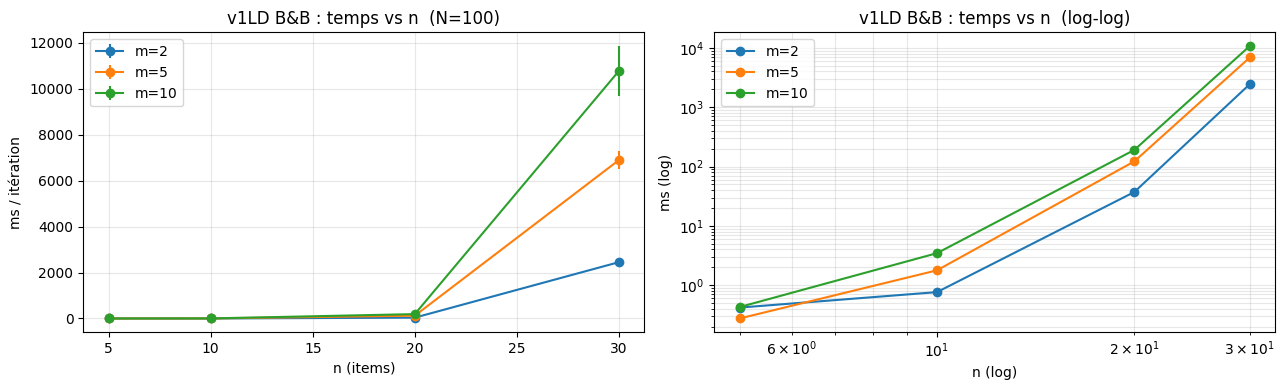

Exposants empiriques en n (pente log-log) :
  m=2 : pente = 4.75
  m=5 : pente = 5.57
  m=10 : pente = 5.53


In [7]:
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for m_val, color in zip(M_VALUES, colors):
    sub = df[df.m == m_val].sort_values('n')
    if sub.empty: continue
    axes[0].errorbar(sub.n, sub.ms, yerr=sub['std'], marker='o',
                     label=f'm={m_val}', color=color)
    axes[1].plot(sub.n, sub.ms, 'o-', label=f'm={m_val}', color=color)

axes[0].set_xlabel('n (items)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1LD B&B : temps vs n  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('n (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1LD B&B : temps vs n  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en n (pente log-log) :')
for m_val in M_VALUES:
    sub = df[df.m == m_val].sort_values('n')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.n.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  m={m_val} : pente = {slope:.2f}')

## 3. Effet de m

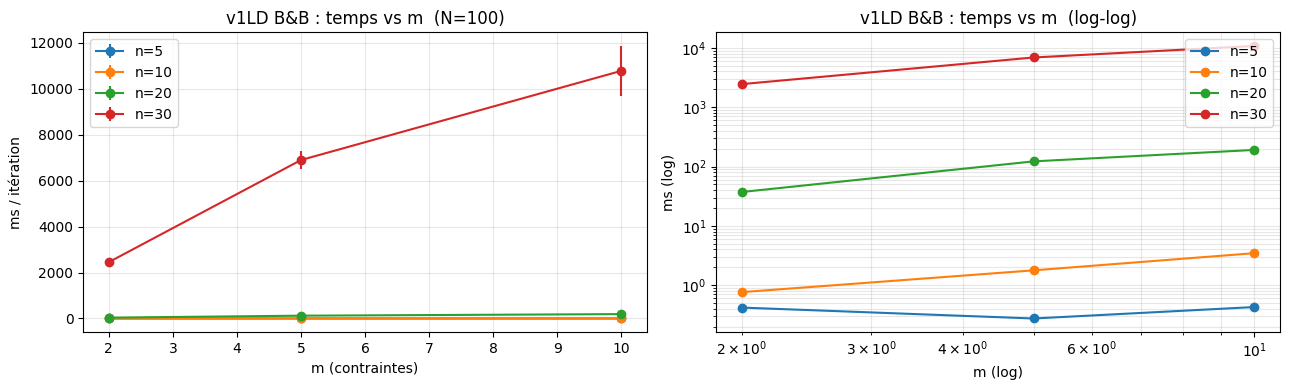

Exposants empiriques en m (pente log-log) :
  n=5 : pente = -0.01  (théorie: ~1)
  n=10 : pente = 0.94  (théorie: ~1)
  n=20 : pente = 1.03  (théorie: ~1)
  n=30 : pente = 0.93  (théorie: ~1)


In [8]:
colors5 = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for n_val, color in zip(N_VALUES, colors5):
    sub = df[df.n == n_val].sort_values('m')
    if sub.empty: continue
    axes[0].errorbar(sub.m, sub.ms, yerr=sub['std'], marker='o',
                     label=f'n={n_val}', color=color)
    axes[1].plot(sub.m, sub.ms, 'o-', label=f'n={n_val}', color=color)

axes[0].set_xlabel('m (contraintes)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1LD B&B : temps vs m  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('m (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1LD B&B : temps vs m  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en m (pente log-log) :')
for n_val in N_VALUES:
    sub = df[df.n == n_val].sort_values('m')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.m.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  n={n_val} : pente = {slope:.2f}  (théorie: ~1)')

## 4. Effet de N (scénarios)

N=   50  v1LD B&B=50.501±5.096 ms
N=  100  v1LD B&B=104.690±7.810 ms
N=  500  v1LD B&B=489.376±10.526 ms
N= 1000  v1LD B&B=1033.224±53.948 ms


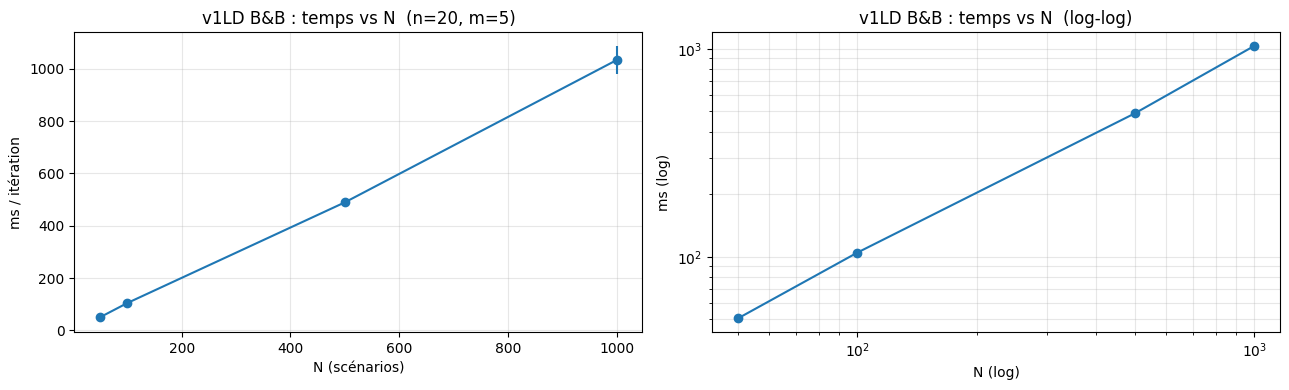

Exposant empirique en N : 1.00  (théorie: ~1)


In [9]:
N_FIX, M_FIX = 20, 5

records_s = []
for S in S_VALUES:
    fname = f'ccmk-song-pisinger-n{N_FIX}-m{M_FIX}-a50-we-r{SEED}-S{S}.txt'
    fpath = os.path.join(ROOT, DATASET_DIR, fname)
    if not os.path.exists(fpath): continue
    c, p, A, b = load_song(fpath)
    ms, std = chrono_ld(c, p, A, b, EPSILON, T_REPS, T_WARMUP)
    records_s.append(dict(S=S, ms=ms, std=std))
    print(f'N={S:5d}  v1LD B&B={ms:.3f}±{std:.3f} ms')

df_s = pd.DataFrame(records_s)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(df_s.S, df_s.ms, yerr=df_s['std'], marker='o')
axes[0].set_xlabel('N (scénarios)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1LD B&B : temps vs N  (n={N_FIX}, m={M_FIX})')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_s.S, df_s.ms, 'o-')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('N (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1LD B&B : temps vs N  (log-log)')
axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

if len(df_s) >= 3:
    slope = np.polyfit(np.log(df_s.S.values.astype(float)),
                       np.log(df_s.ms.values), 1)[0]
    print(f'Exposant empirique en N : {slope:.2f}  (théorie: ~1)')

## 5. Tableau récapitulatif

In [10]:
print(df[['n', 'm', 'N', 'W_max', 'ms', 'std']].to_string(
    index=False, float_format=lambda x: f'{x:.3f}'))

 n  m   N  W_max        ms      std
 5  2 100   1196     0.419    0.520
 5  5 100   1859     0.275    0.117
 5 10 100   1884     0.429    0.197
10  2 100   3220     0.765    0.119
10  5 100   3220     1.781    0.234
10 10 100   3220     3.467    0.265
20  2 100   5386    37.272    1.975
20  5 100   5537   122.295   11.050
20 10 100   5537   190.649   19.564
30  2 100   8198  2451.269  132.248
30  5 100   8198  6893.288  404.827
30 10 100   8198 10773.408 1085.149
